# MasterClass FinTech · Session 1 Assignments

**Name:** Amirhossein Rezazadeh

1. California Cities: top 5 cities by water area
2. Billionaires: 10 largest industries + Other
3. Online Retail: monthly retention rate of UK customers

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

base = "/content/MasterClass-FinTech-01/session_1"

---
## 1 · California Cities

**Process:** inspect the water-area columns, fix the missing values, rank the cities by `area_water_km2`, plot the top 5.

In [2]:
cities = pd.read_csv(f"../california_cities/california_cities.csv", index_col=0)
print(cities.shape)
cities.head()

(482, 13)


,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


In [3]:
cols = ["area_water_sq_mi", "area_water_km2", "area_water_percent"]
print(cities[cols].dtypes, "\n")
print(cities[cols].isna().sum())
cities.loc[cities["area_water_km2"].isna(), ["city", "area_water_sq_mi", "area_water_km2"]]

area_water_sq_mi      float64
area_water_km2        float64
area_water_percent    float64
dtype: object 

area_water_sq_mi      1
area_water_km2        4
area_water_percent    5
dtype: int64


,city,area_water_sq_mi,area_water_km2
237,LosAltos,0.000,NaN
370,SanFrancisco,185.020,NaN
393,SantaMonica,0.001,NaN
443,UnionCity,0.000,NaN


Four cities have no `area_water_km2`, but all of them have `area_water_sq_mi`, so the gap is filled with `sq mi × 2.58999`. One of the four is **San Francisco**, which would otherwise disappear from the ranking.

In [4]:
cities["area_water_km2"] = cities["area_water_km2"].fillna(cities["area_water_sq_mi"] * 2.58999)
print("Missing after filling:", cities["area_water_km2"].isna().sum())

top5 = cities.nlargest(5, "area_water_km2")[["city", "area_water_km2"]].reset_index(drop=True)
top5["city"] = top5["city"].str.replace(r"(?<=[a-z])(?=[A-Z])", " ", regex=True)
top5.index += 1
top5.round(1)

Missing after filling: 0


,city,area_water_km2
1,San Francisco,479.2
2,San Diego,122.3
3,Los Angeles,88.0
4,Newport Beach,75.6
5,Coronado,64.1


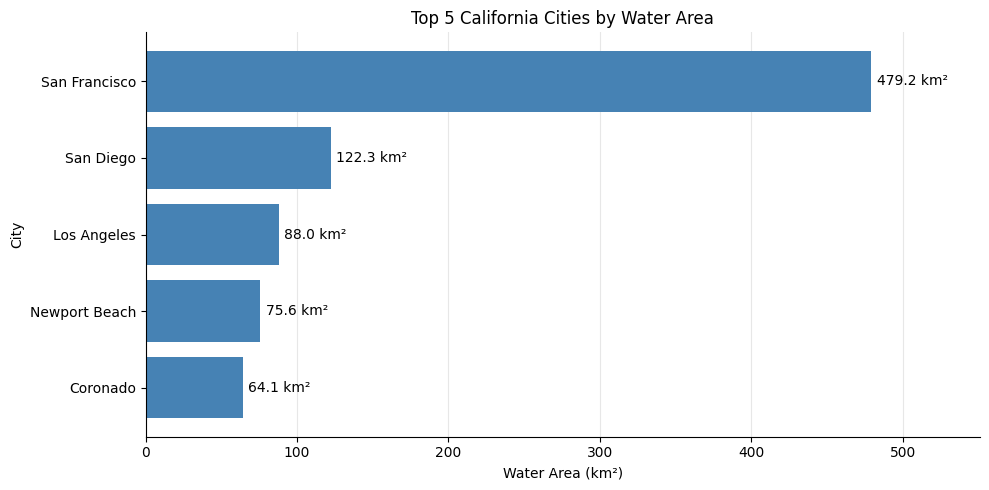

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top5["city"], top5["area_water_km2"], color="steelblue")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.1f km²", padding=4)
ax.set_xlim(0, top5["area_water_km2"].max() * 1.15)
ax.set_xlabel("Water Area (km²)")
ax.set_ylabel("City")
ax.set_title("Top 5 California Cities by Water Area")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Result:** San Francisco (479.2 km²) is far ahead of San Diego (122.3), Los Angeles (88.0), Newport Beach (75.6) and Coronado (64.1). All five are coastal or bay cities whose boundaries include large areas of water.

---
## 2 · Billionaires

**Process:** count billionaires per industry, keep the 10 largest and group all the others into **Other**. `Industry` has no missing values (only `Age` does), so all 2,755 rows are used.

In [6]:
bill = pd.read_csv(f"../billionaires/Billionaire.csv")
print(bill.shape)
display(bill.head())
bill.isna().sum().to_frame("Missing Values")

(2755, 7)


,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,$177 B,United States,Amazon,1,57.0,Technology
1,Elon Musk,$151 B,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,$150 B,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,$124 B,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,$97 B,United States,Facebook,5,36.0,Technology


,Missing Values
Name,0
NetWorth,0
Country,0
Source,0
Rank,0
Age,79
Industry,0


In [7]:
counts = bill["Industry"].value_counts()
print("Distinct industries:", len(counts))

dist = counts.head(10).copy()
dist["Other"] = counts.iloc[10:].sum()
assert dist.sum() == len(bill)
dist.rename("Billionaire Count").to_frame()

Distinct industries: 18


,Billionaire Count
Industry,
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188
Energy,100


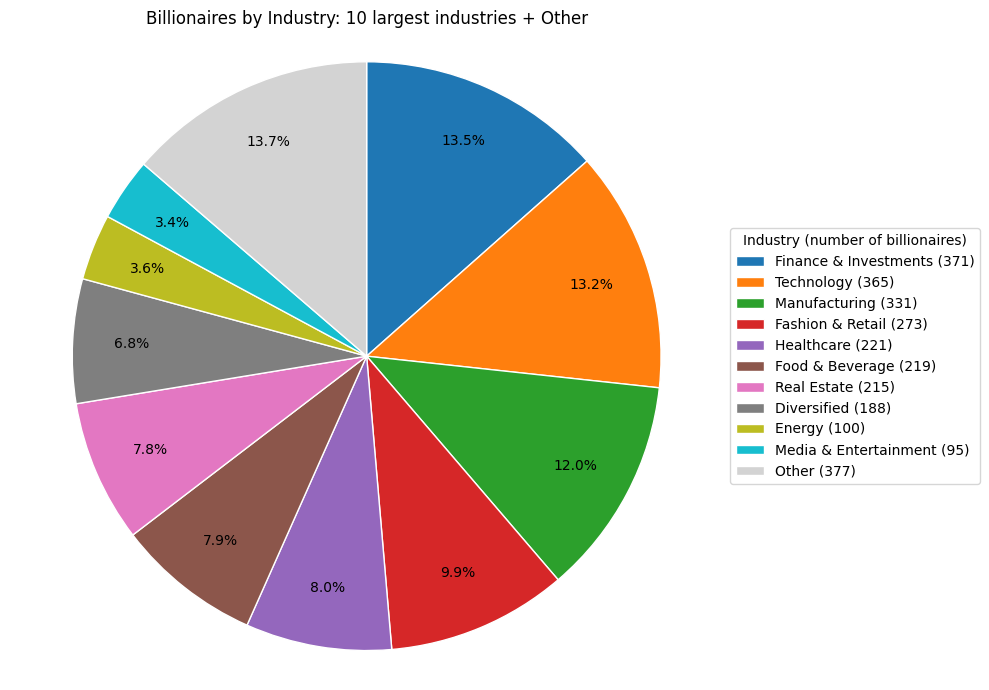

In [8]:
colors = list(plt.cm.tab10.colors) + ["lightgray"]

fig, ax = plt.subplots(figsize=(10, 7))
wedges, _, _ = ax.pie(
    dist.values,
    colors=colors,
    autopct="%1.1f%%",
    pctdistance=0.8,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white"},
)
ax.legend(
    wedges,
    [f"{k} ({v})" for k, v in dist.items()],
    title="Industry (number of billionaires)",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)
ax.set_title("Billionaires by Industry: 10 largest industries + Other")
ax.axis("equal")
plt.tight_layout()
plt.show()

**Result:** Finance & Investments (371), Technology (365) and Manufacturing (331) are the largest industries. **Other** (377 billionaires, 8 small industries) is a bucket and is kept as the last, grey slice.

---
## 3 · Online Retail: Monthly Retention Rate (UK)

$$Retention\ Rate = \frac{Customers\ active\ in\ both\ this\ and\ the\ previous\ month}{Customers\ active\ this\ month}$$

**Process:** keep UK rows with a `CustomerID`, build a customer × month activity table, count active and retained customers per month, then plot the rate.

In [9]:
retail = pd.read_csv(f"../online_retail/OnlineRetail.csv", encoding="ISO-8859-1")
print(retail.shape)
retail.isna().sum()

(541909, 8)


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [10]:
uk = retail.loc[retail["Country"] == "United Kingdom"].copy()
print("UK rows:", len(uk), "| without CustomerID (dropped):", uk["CustomerID"].isna().sum())

uk = uk.dropna(subset=["CustomerID", "InvoiceDate"])
uk["InvoiceDate"] = pd.to_datetime(uk["InvoiceDate"])
uk["CustomerID"] = uk["CustomerID"].astype(int)
uk["Month"] = uk["InvoiceDate"].dt.to_period("M")
print("Period:", uk["InvoiceDate"].min(), "->", uk["InvoiceDate"].max())

UK rows: 495478 | without CustomerID (dropped): 133600
Period: 2010-12-01 08:26:00 -> 2011-12-09 12:49:00


In [11]:
act = pd.crosstab(uk["CustomerID"], uk["Month"]).gt(0)
m = act.columns

ret = pd.DataFrame({"Total_Customers": act.sum().iloc[1:]})
ret["Retained_Customers"] = [(act[a] & act[b]).sum() for a, b in zip(m[:-1], m[1:])]
ret["Retention_Rate"] = ret["Retained_Customers"] / ret["Total_Customers"] * 100
ret.round(2)

,Total_Customers,Retained_Customers,Retention_Rate
Month,,,
2011-01,684,322,47.08
2011-02,714,263,36.83
2011-03,923,305,33.04
2011-04,817,310,37.94
2011-05,985,369,37.46
2011-06,943,417,44.22
2011-07,899,379,42.16
2011-08,867,391,45.10
2011-09,1177,417,35.43


The data stops on **9 December 2011**, so December 2011 is incomplete (its 65% rate is not comparable) and is excluded from the chart.

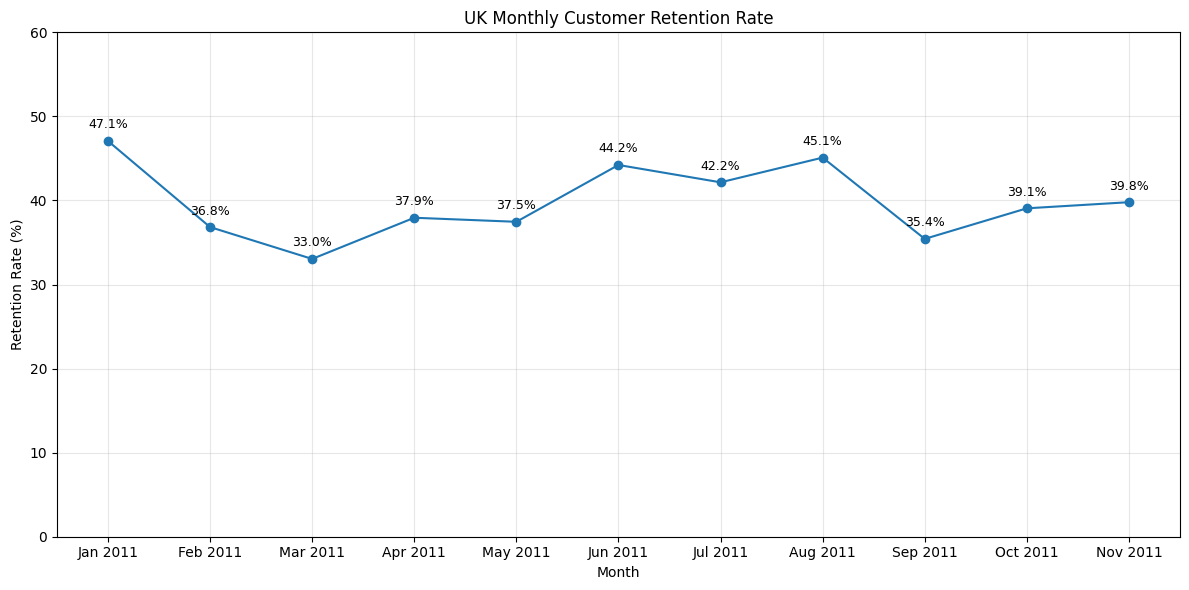

In [12]:
plot_df = ret.drop(index=pd.Period("2011-12"))
labels = plot_df.index.strftime("%b %Y")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(labels, plot_df["Retention_Rate"], marker="o", color="tab:blue")
for x, y in zip(labels, plot_df["Retention_Rate"]):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_ylim(0, 60)
ax.set_xlabel("Month")
ax.set_ylabel("Retention Rate (%)")
ax.set_title("UK Monthly Customer Retention Rate")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
rate = plot_df["Retention_Rate"]
print("Best month:", rate.idxmax(), round(rate.max(), 2), "%")
print("Lowest month:", rate.idxmin(), round(rate.min(), 2), "%")
print("Average:", round(rate.mean(), 2), "%")

Best month: 2011-01 47.08 %
Lowest month: 2011-03 33.04 %
Average: 39.83 %


**Result:** between 33% and 47% of the customers active in a month had also bought in the previous month (average 39.8%). Retention is highest in January 2011 (47.1%) and lowest in March 2011 (33.0%); it rises in June–August and drops in September (35.4%) when many new customers join.
Overall, it looks like a good number of customers come back the next month, but this changes a bit from month to month :)))
= = = // Amirhoosein Rezazade // = = =